# Evolution of star clusters in arbitrary tidal fields

Florent Renaud, Mark Gieles, Christian Boily. 2011
doi:10.1111/j.1365-2966.2011.19531.x

- play with the results of the paper 
- make some jacobi surfaces 
- make an animation of a surface in the cluster frame 
- make an animation of the football flying through space 

In [3]:
import numpy, matplotlib.pyplot as plt, agama, os
from astropy import constants as cnst 
from astropy import units as u 
from scipy.optimize import root,fsolve,brentq
import matplotlib.gridspec as gridspec
from matplotlib import patches
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{txfonts}",
})

In [4]:
# construct the tidal tensor 
def hessian_galactic_potential(pot, pos):
    dFxdx,dFydy,dFzdz,dFxdy,dFydz,dFzdx=pot.eval(pos,der=True).T
    dFydx       =   dFxdy
    dFxdz       =   dFzdx
    dFzdy       =   dFydz
    column1     =   numpy.array([dFxdx, dFydx, dFzdx])
    column2     =   numpy.array([dFxdy, dFydy, dFzdy])
    column3     =   numpy.array([dFxdz, dFydz, dFzdz])
    tidalTensor =   numpy.column_stack([column1,column2,column3])
    return -tidalTensor

def hessian_centrifugal(Omega):
    omega = numpy.linalg.norm(Omega)
    term1=omega**2 * numpy.eye(3)
    term2 = numpy.linalg.outer(Omega,Omega)
    return (term2 - term1)

def effective_potential_with_effective_tensor(pos, Hessian, pot_cluster):  # p: (N,3)
    pos = numpy.atleast_2d(pos)
    quad = 0.5*numpy.einsum('ni,ij,nj->n', pos, Hessian, pos)
    return pot_cluster.potential(pos) + quad

def F_total_cluster_frame(pos, Hessian, pot_cluster):
    F_hess=-(Hessian@pos.T).T
    F_gc = pot_cluster.eval(pos,acc=True)
    return F_hess+F_gc

def get_omega_from_orbit(posvel):
    return numpy.linalg.cross(posvel[0:3],posvel[3:6]) / numpy.linalg.norm(posvel[0:3])**2

In [5]:
def get_L1(Hess_eff,pot_cluster):
    eigenvalues, eigenvectors   =   numpy.linalg.eigh(Hess_eff)
    eigenvector                 =   eigenvectors[:, 0]
    
    eigenvector/=numpy.linalg.norm(eigenvector)
    lambda1 = -eigenvalues[0]
    
    rJ = (G*massCluster/lambda1)**(1/3)
    rJ_guess = rJ * eigenvector # makes it a vector
    
    L1 = fsolve(F_total_cluster_frame,rJ_guess,args=(Hess_eff,pot_cluster))
    EL1 =effective_potential_with_effective_tensor(L1,Hess_eff,pot_cluster)
    return L1, EL1

In [ ]:
def make_vector_field_that_is_aligned_with_the_eigenvectors(Hess_eff,L1,npoints=100):
    "Because, I don't want the surface to extend beyond the jacobi surface"
    _, eigenvectors   =   numpy.linalg.eigh(Hess_eff)
    rJ = numpy.linalg.norm(L1)
    # tilt the football so we only get the axis and don't go beyond for the jacobi surface
    dx_phi = numpy.linspace(-rJ,rJ,npoints)
    dy_phi = numpy.linspace(-rJ,rJ,npoints)
    DX,DY = numpy.meshgrid(dx_phi,dy_phi)
    pos_phi = numpy.column_stack((DX.flatten(), DY.flatten(), 0*DY.flatten()))
    # alle the rotation matric of the eivenvectors 
    pos_phi = (eigenvectors @ pos_phi.T).T
    DX = pos_phi[:,0]; DY=pos_phi[:,1]
    return DX,DY

def get_normalized_vector_field(pos, Hess, pot_cluster):
    F_eff =   -(Hess@pos.T).T
    F_gc  =   pot_cluster.eval(pos,acc=True)
    F_tot =   F_eff+F_gc
    F_tot_norm = numpy.divide(F_tot.T,numpy.linalg.norm(F_tot,axis=1),).T
    return F_tot_norm

set units 

In [7]:
unitL = u.kpc
unitV = u.km/u.s
unitM = u.Msun
G=cnst.G.to(unitV**2 * (unitL/unitM)).value
agama.setUnits(mass=1, length=1, velocity=1)

In [8]:
# initialize our potential 
potential   =   "McMillan17.ini"
path        =   agama.__path__[0] + "/data/" + "McMillan17.ini"
pot         =   agama.Potential(path)
massCluster =   1e5
scaleRadius =   5e-3
pot_cluster =   agama.Potential(type="plummer", mass=massCluster, scaleRadius=scaleRadius)

## View vector field in the plane

In [9]:
# pick a position of the globular cluster, assume an angular velocity at this position
pos_cluster =   numpy.array([3,2,0])
Omega       =   numpy.array([0,0,-37.5])

In [10]:
# compute a piece of the orbit 
# get the circular velocity for the cluster 
force   =   pot.eval(pos_cluster,acc=True)
vc      =   numpy.sqrt(numpy.abs(numpy.dot(pos_cluster,force)))
vel     =   0.5*vc*numpy.linalg.cross(pos_cluster,[0,0,1])/numpy.linalg.norm(pos_cluster)
ic      =   numpy.hstack((pos_cluster,vel))
Tcirc   =   pot.Tcirc(ic)
timestamps,orb=agama.orbit(ic=ic,potential=pot,time=3*Tcirc, trajsize=int(1e3))

In [11]:
# get the tensors for the centrigudal force and the galaxy's tidal field
Hess_cen    =   hessian_centrifugal(Omega)
Hess_mw     =   hessian_galactic_potential(pot,pos_cluster)
Hess_eff    =   (Hess_mw + Hess_cen)

In [12]:
L1,EL1 = get_L1(Hess_eff,pot_cluster)
npoints = 100
DX,DY = make_vector_field_that_is_aligned_with_the_eigenvectors(Hess_eff,L1,npoints=npoints)
pos = numpy.column_stack((DX.flatten(),DY.flatten(),0*DX.flatten()))
phi = effective_potential_with_effective_tensor(pos,Hess_eff,pot_cluster)
phi = phi.reshape((npoints,npoints))
DX = DX.reshape(npoints,npoints)
DY = DY.reshape(npoints,npoints)

In [ ]:
rJ = numpy.linalg.norm(L1)
factor=2
# create a vector field for evaluating the surface
dx_vec          =       numpy.linspace(-factor*rJ,factor*rJ,20)
DX_VEC,DY_VEC   =       numpy.meshgrid(dx_vec,dx_vec)
pos             =       numpy.column_stack((DX_VEC.flatten(),DY_VEC.flatten(),0*DX_VEC.flatten()))

F_cen   =   -(Hess_cen@pos.T).T
F_tidal =   -(Hess_mw@pos.T).T
F_gc    =   pot_cluster.eval(pos,acc=True)
F_tot   =   F_cen+F_tidal+F_gc
F_tot_norm      =   numpy.divide(F_tot.T,numpy.linalg.norm(F_tot,axis=1),).T

F_gc_norm       =   numpy.divide(F_gc.T,numpy.linalg.norm(F_gc,axis=1),).T
F_tidal_norm    =   numpy.divide(F_tidal.T,numpy.linalg.norm(F_tidal,axis=1),).T
F_cen_norm      =   numpy.divide(F_cen.T,numpy.linalg.norm(F_cen,axis=1),).T
F_tot_norm      =   numpy.divide(F_tot.T,numpy.linalg.norm(F_tot,axis=1),).T

# make a circle for the cluster's radius to scale 
ntheta = 100
theta = numpy.linspace(0,2*numpy.pi,int(ntheta))
cluter_circ=scaleRadius*numpy.column_stack((numpy.cos(theta), numpy.sin(theta)))

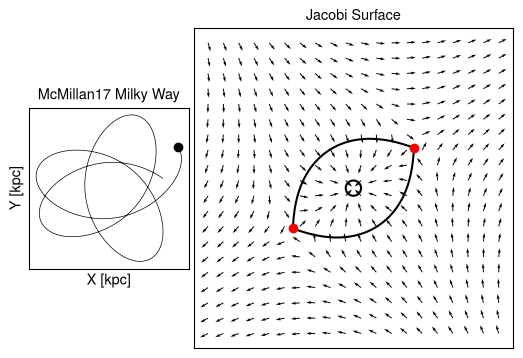

In [22]:
path="effective_potential_linearized"
fname = path+"/vector_field_{:04d}.png"
framecount = 0 

fig=plt.figure(figsize=((8.25 -2),2/3 * (8.25 -2)))
gs = gridspec.GridSpec(1,2,width_ratios = (1,2),wspace=1/50)
axis=fig.add_subplot(gs[0])
axis2=fig.add_subplot(gs[1])

# PLOT THE BIGGEST ELEMENTS AND REMOVE THEM TO INITATE THE AXES
line,=axis.plot(orb[:,0],orb[:,1],color="k",linewidth=0.5)
quiv = axis2.quiver(DX_VEC,DY_VEC,F_tot_norm[:,0],F_tot_norm[:,1])

line.remove()
quiv.remove()
# set the size
axis.set(aspect="equal",yticks=[],xticks=[])
axis2.set(yticks=[],xticks=[],aspect='equal')
# save the blank axis
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

axis.set(xlabel="X [kpc]", ylabel= "Y [kpc]")
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

scat=axis.scatter(ic[0],ic[1],zorder=10,color="k")
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

line,=axis.plot(orb[:,0],orb[:,1],color=scat.get_facecolor(),linewidth=0.5)
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

axis.set(title="McMillan17 Milky Way")
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

# add the cluster, to scale
axis2.plot(cluter_circ[:,0],cluter_circ[:,1],color="k")
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

quiv = axis2.quiver(DX_VEC,DY_VEC,F_tot_norm[:,0],F_tot_norm[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1
quiv.remove()

axis2.set(title="Centrifugal")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_cen[:,0],F_cen[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

quiv.remove()
axis2.set(title="Tidal")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_tidal[:,0],F_tidal[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

quiv.remove()
axis2.set(title="Gravitational")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_gc[:,0],F_gc[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

# scale it down, add them, and adjust them 

quiv.remove()
axis2.set(title="Gravitational")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_gc_norm[:,0],F_gc_norm[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1


quiv.remove()
axis2.set(title="Gravitational + Tidal")
F_temp = F_gc + F_tidal
F_temp = numpy.divide(F_temp.T,numpy.linalg.norm(F_temp,axis=1),).T
quiv = axis2.quiver(DX_VEC,DY_VEC,F_temp[:,0],F_temp[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1   

quiv.remove()
axis2.set(title="Gravitational + Tidal + Centrifugal")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_tot_norm[:,0],F_tot_norm[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1   

quiv.remove()
axis2.set(title="Gravitational + Tidal + Centrifugal")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_tot[:,0],F_tot[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1

quiv.remove()
axis2.set(title="Gravitational + Tidal + Centrifugal")
quiv = axis2.quiver(DX_VEC,DY_VEC,F_tot_norm[:,0],F_tot_norm[:,1])
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1  

# add the lagrange points
axis2.set(title="")
axis2.scatter(L1[0],L1[1],color="r",zorder=10)
axis2.scatter(-L1[0],-L1[1],color="r",zorder=10)
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1  
axis2.set(title="Lagrange points")
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1  

axis2.contour(DX, DY, phi, levels=[EL1[0]], colors="k",linestyle="-")
axis2.set(title="Jacobi Surface")
fig.savefig(fname.format(framecount),dpi=300)
framecount+=1  


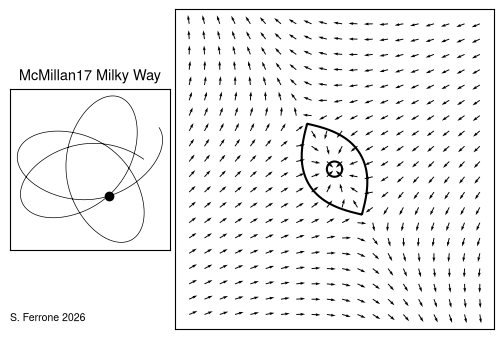

In [ ]:
# make the animaiton 
os.makedirs("effective_potential_linearized/disc_anim/",exist_ok=True)

# the things that won't change each frame
# get the hessian at our starting position 

# STUFF FOR INITIATING 
Hess_cen = hessian_centrifugal(Omega)
Hess_mw = hessian_galactic_potential(pot,ic[0:3])
Hess_eff = Hess_mw + Hess_cen
L1,EL1 = get_L1(Hess_eff, pot_cluster)
rJ_largest = numpy.linalg.norm(L1)

# create a vector field for evaluating the surface
factor=2;nvec = 20 
dx_vec          =       numpy.linspace(-factor*rJ_largest,factor*rJ_largest,nvec)
DX_VEC,DY_VEC   =       numpy.meshgrid(dx_vec,dx_vec)
pos_vector_field=       numpy.column_stack((DX_VEC.flatten(),DY_VEC.flatten(),0*DX_VEC.flatten()))

ntheta = 100
theta = numpy.linspace(0,2*numpy.pi,int(ntheta))
cluter_circ=scaleRadius*numpy.column_stack((numpy.cos(theta), numpy.sin(theta)))


## INITIATE THE FIGURE
fig=plt.figure(figsize=((8.25 -2),2/3 * (8.25 -2)))
sim_index=0
gs = gridspec.GridSpec(1,2,width_ratios = (1,2),wspace=1/50)
axis=fig.add_subplot(gs[0])
axis2=fig.add_subplot(gs[1])

# PLOT THINGS THAT WILL REMAIN CONSTANT 
line,=axis.plot(orb[:,0],orb[:,1],color=scat.get_facecolor(),linewidth=0.5)
axis.set(aspect="equal",yticks=[],xticks=[])
axis2.set(yticks=[],xticks=[],aspect='equal')
fig.text(0.125,0.125,s="S. Ferrone 2026",fontdict={"size":8},ha="left",va="bottom")
axis2.plot(cluter_circ[:,0],cluter_circ[:,1],color="k")
axis.set(title="McMillan17 Milky Way")

# THE LOOP! 
SIM_INDEX = 100
# update the tidal field 
Hess_mw = hessian_galactic_potential(pot,orb[SIM_INDEX,0:3])
Hess_eff = Hess_mw + Hess_cen
L1,EL1 = get_L1(Hess_eff, pot_cluster)
# get the jacobi surface 
dx_jacobi, dy_jacobi = make_vector_field_that_is_aligned_with_the_eigenvectors(Hess_eff, L1, npoints)
pos_jacobi = numpy.column_stack((dx_jacobi, dy_jacobi,0*dy_jacobi))
phi = effective_potential_with_effective_tensor(pos_jacobi, Hess_eff, pot_cluster)
dx_jacobi = numpy.reshape(dx_jacobi,(npoints,npoints))
dy_jacobi = numpy.reshape(dy_jacobi, (npoints,npoints))
phi = numpy.reshape(phi, (npoints,npoints))

f_norm  = get_normalized_vector_field(pos_vector_field, Hess_eff, pot_cluster)

# update the plot 
quiv    =   axis2.quiver(pos_vector_field[:,0],pos_vector_field[:,1],f_norm[:,0],f_norm[:,1])
scat    =   axis.scatter(orb[SIM_INDEX,0],orb[SIM_INDEX,1],zorder=10,color="k")
axis2.contour(dx_jacobi, dy_jacobi, phi, levels=[EL1[0]], colors="k",linestyle="-");
# save the frame

# clear the axes 

In [29]:
fps = 60
orb.shape[0] / fps

16.666666666666668